<a href="https://colab.research.google.com/github/Saiprasanna17/CSA4705-Deep-Learning/blob/main/DL_CO3_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**33. Comparison of SGD, RMSprop and Adam Optimizers**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD Accuracy: 0.69
RMSprop Accuracy: 0.86
Adam Accuracy: 0.87


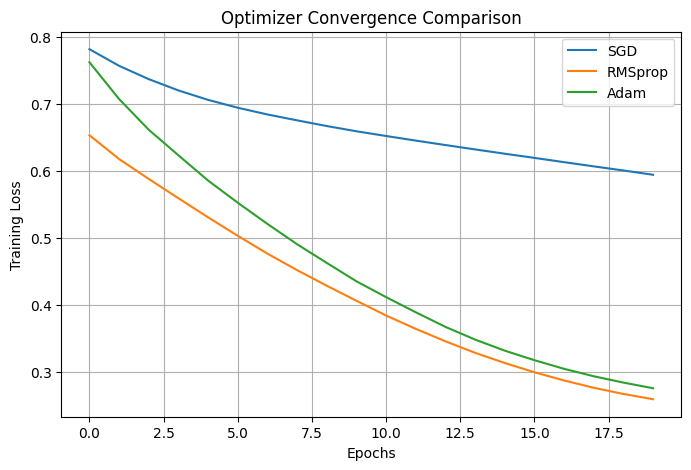

In [11]:

import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=500, n_features=10,
                           random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

optimizers = ['SGD', 'RMSprop', 'Adam']
results = {}

for opt in optimizers:
    model = Sequential([
        Dense(16, activation='relu', input_shape=(10,)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer=opt,
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(
        X_train, y_train,
        epochs=20,
        verbose=0
    )

    results[opt] = history.history['loss']

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    print(opt, "Accuracy:", round(accuracy, 4))

plt.figure(figsize=(8, 5))

for opt in optimizers:
    plt.plot(results[opt], label=opt)

plt.title("Optimizer Convergence Comparison")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.legend()
plt.grid()
plt.show()

**34. Handwritten PIN Code Recognition Using Deep Feedforward Neural Network**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=3)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)
print("Prediction:", model.predict(x_test[:1]).argmax())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9304 - loss: 0.2387
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9688 - loss: 0.1022
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9777 - loss: 0.0704
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9711 - loss: 0.0972
Test Accuracy: 0.9710999727249146
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Prediction: 7


**35. Dropout Regularization to Prevent Overfitting**

Without Dropout Accuracy: 0.845
With Dropout Accuracy: 0.855


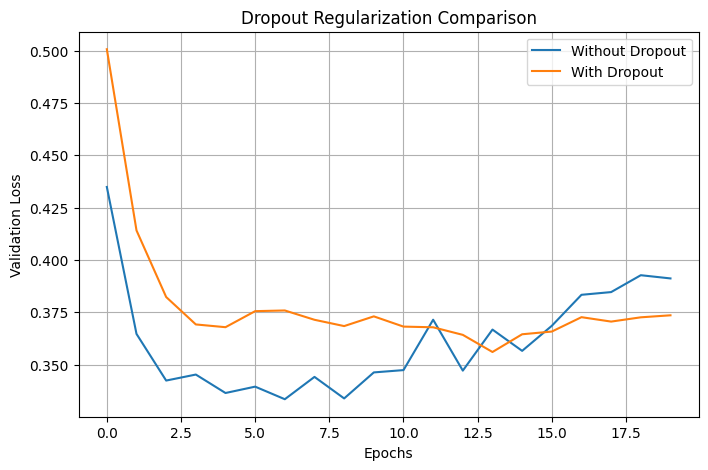

In [12]:

import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000,
                           n_features=20,
                           random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

results = {}

for dropout in [False, True]:
    model = Sequential()
    model.add(Dense(128, activation='relu',
                    input_shape=(20,)))

    if dropout:
        model.add(Dropout(0.5))

    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=20,
        verbose=0
    )

    name = "With Dropout" if dropout else "Without Dropout"
    results[name] = history.history['val_loss']

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    print(name, "Accuracy:", round(accuracy, 4))

plt.figure(figsize=(8, 5))

for name, values in results.items():
    plt.plot(values, label=name)

plt.title("Dropout Regularization Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid()
plt.show()

**36. L2 Regularization in Neural Networks**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=500, n_features=10,
                           random_state=42)

model = Sequential([
    Dense(16, activation='relu', input_shape=(10,),
          kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu',
          kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(X, y, epochs=5, verbose=1)

print("Model Accuracy:", model.evaluate(X, y, verbose=0)[1])
print("L2 Regularization Applied Successfully")

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6520 - loss: 0.8451
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7160 - loss: 0.7931
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7600 - loss: 0.7490 
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7940 - loss: 0.7114 
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8120 - loss: 0.6761 
Model Accuracy: 0.8259999752044678
L2 Regularization Applied Successfully


**37. Comparison of Models With and Without Regularization**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=20,
                           random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

for regularization in [False, True]:
    model = Sequential([
        Dense(64, activation='relu', input_shape=(20,)),
        Dropout(0.5) if regularization else Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=5, verbose=0)

    train_acc = model.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = model.evaluate(X_test, y_test, verbose=0)[1]

    print("Regularization:", regularization)
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)

Regularization: False
Training Accuracy: 0.893750011920929
Testing Accuracy: 0.8550000190734863
Regularization: True
Training Accuracy: 0.8662499785423279
Testing Accuracy: 0.8399999737739563


**38. CNN for Handwritten Digit Recognition**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=3)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)
print("Predicted Digit:", model.predict(x_test[:1]).argmax())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 39s 20ms/step - accuracy: 0.9495 - loss: 0.1734
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 19ms/step - accuracy: 0.9816 - loss: 0.0608
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.9870 - loss: 0.0407
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9840 - loss: 0.0485
Test Accuracy: 0.984000027179718
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted Digit: 7


**39. Convolution and Pooling Operations**

In [ ]:
import numpy as np
from scipy.signal import convolve2d

image = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 16]
])

kernel = np.array([
    [1, 0],
    [0, -1]
])

conv = convolve2d(image, kernel, mode='valid')

print("Original Image:")
print(image)

print("Convolution Output:")
print(conv)

pool = np.maximum.reduceat(
    np.maximum.reduceat(conv, [0, 2], axis=0),
    [0, 2], axis=1
)

print("Pooled Output:")
print(pool)

Original Image:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
Convolution Output:
[[5 5 5]
 [5 5 5]
 [5 5 5]]
Pooled Output:
[[5 5]
 [5 5]]


**40. Comparison of Max Pooling and Average Pooling**

Original Image:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]

Max Pooling Output:
[[ 6.  8.]
 [14. 16.]]

Average Pooling Output:
[[ 3.5  5.5]
 [11.5 13.5]]


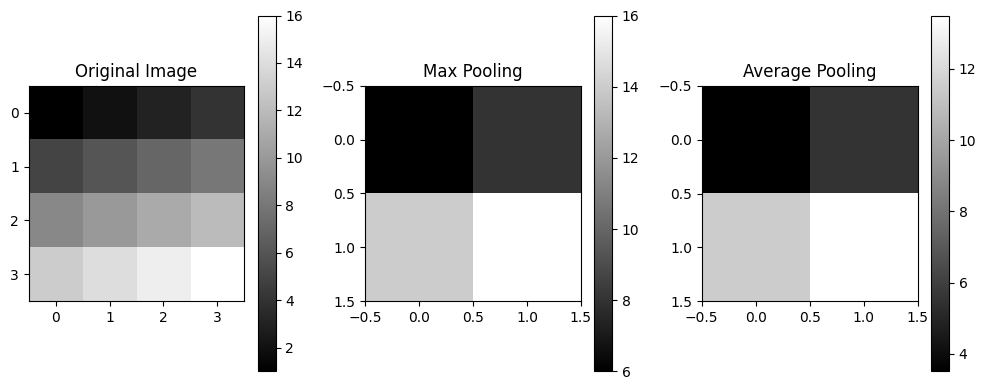

In [13]:

import numpy as np
import matplotlib.pyplot as plt

image = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 16]
])

max_pool = np.zeros((2, 2))
avg_pool = np.zeros((2, 2))

for i in range(2):
    for j in range(2):
        block = image[i*2:i*2+2, j*2:j*2+2]
        max_pool[i, j] = np.max(block)
        avg_pool[i, j] = np.mean(block)

print("Original Image:")
print(image)

print("\nMax Pooling Output:")
print(max_pool)

print("\nAverage Pooling Output:")
print(avg_pool)

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(max_pool, cmap='gray')
plt.title("Max Pooling")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(avg_pool, cmap='gray')
plt.title("Average Pooling")
plt.colorbar()

plt.tight_layout()
plt.show()

**41. Cats and Dogs Image Classification Using CNN**

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

train_mask = (y_train.flatten() == 3) | (y_train.flatten() == 5)
test_mask = (y_test.flatten() == 3) | (y_test.flatten() == 5)

x_train = x_train[train_mask] / 255.0
y_train = (y_train[train_mask].flatten() == 5).astype(int)

x_test = x_test[test_mask] / 255.0
y_test = (y_test[test_mask].flatten() == 5).astype(int)

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=3)

print("Test Accuracy:", model.evaluate(x_test, y_test)[1])

prediction = model.predict(x_test[:1])[0][0]
print("Prediction:", "Dog" if prediction > 0.5 else "Cat")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 34s 0us/step
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.5945 - loss: 0.6673
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.6522 - loss: 0.6233
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.6809 - loss: 0.5905
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6715 - loss: 0.5864
Test Accuracy: 0.671500027179718
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Prediction: Cat


**42. Effect of Different Filter Sizes in CNN**

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train[:5000].reshape(-1, 28, 28, 1) / 255.0
x_test = x_test[:1000].reshape(-1, 28, 28, 1) / 255.0

y_train = y_train[:5000]
y_test = y_test[:1000]

for size in [3, 5]:
    model = Sequential([
        Conv2D(32, (size, size), activation='relu',
               input_shape=(28, 28, 1)),
        MaxPooling2D(),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    model.fit(x_train, y_train, epochs=2, verbose=0)

    accuracy = model.evaluate(x_test, y_test, verbose=0)[1]

    print("Filter Size:", size)
    print("Accuracy:", accuracy)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Filter Size: 3
Accuracy: 0.9210000038146973
Filter Size: 5
Accuracy: 0.9449999928474426


**43. Evaluation of CNN Using Performance Metric**

Accuracy: 0.75
Precision: 0.75
Recall: 0.75
F1 Score: 0.75

Confusion Matrix:
[[3 1]
 [1 3]]


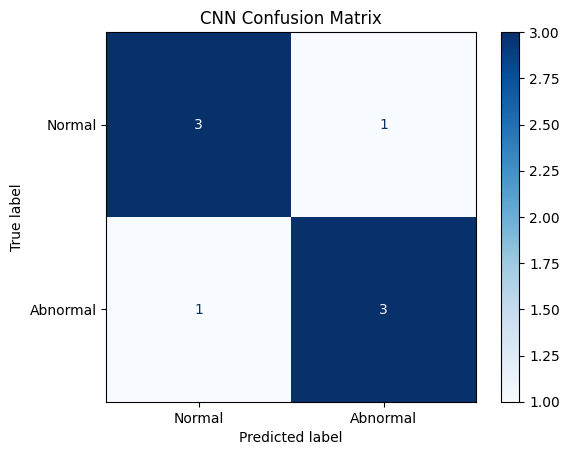

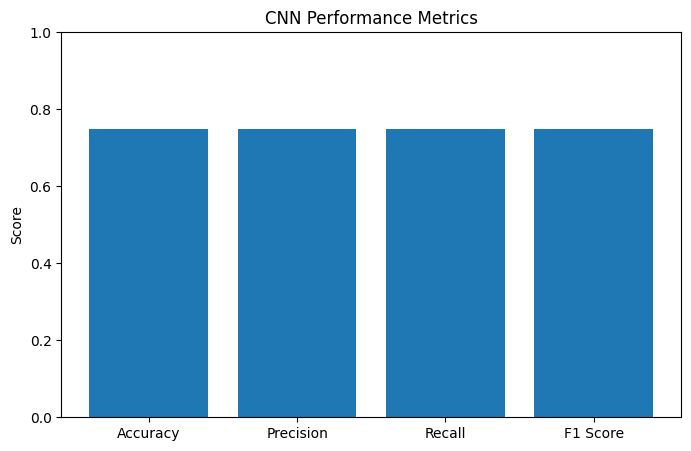

In [14]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

actual = np.array([1, 0, 1, 1, 0, 1, 0, 0])
predicted = np.array([1, 0, 1, 0, 0, 1, 1, 0])

accuracy = accuracy_score(actual, predicted)
precision = precision_score(actual, predicted)
recall = recall_score(actual, predicted)
f1 = f1_score(actual, predicted)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

cm = confusion_matrix(actual, predicted)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Abnormal"]
)

disp.plot(cmap='Blues')
plt.title("CNN Confusion Matrix")
plt.show()

metrics = [accuracy, precision, recall, f1]
names = ["Accuracy", "Precision", "Recall", "F1 Score"]

plt.figure(figsize=(8, 5))
plt.bar(names, metrics)
plt.ylim(0, 1)
plt.title("CNN Performance Metrics")
plt.ylabel("Score")
plt.show()

**44. Batch Normalization in Deep CNN**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Without Batch Normalization
Accuracy: 0.924
With Batch Normalization
Accuracy: 0.922


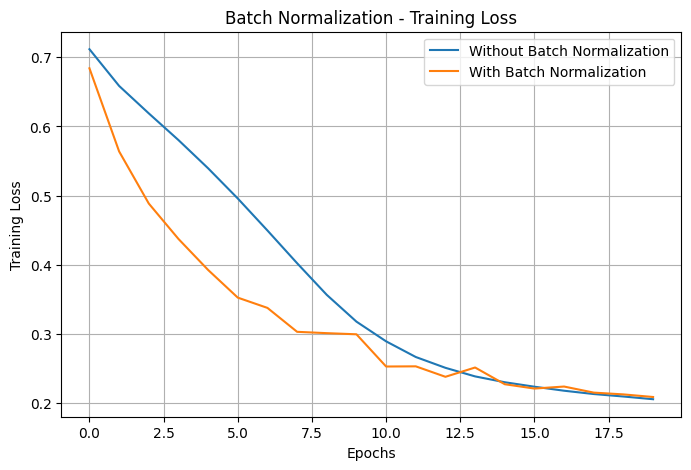

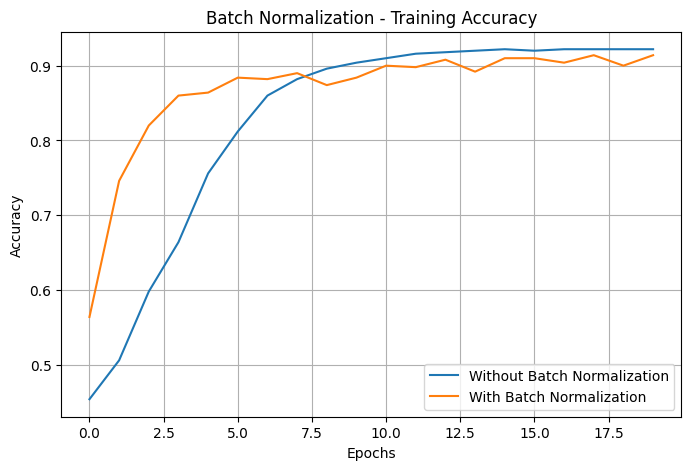

In [15]:

import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=500,
                           n_features=10,
                           random_state=42)

results = {}

for use_bn in [False, True]:
    model = Sequential()

    model.add(Dense(32, activation='relu',
                    input_shape=(10,)))

    if use_bn:
        model.add(BatchNormalization())

    model.add(Dense(16, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(X, y, epochs=20, verbose=0)

    name = "With Batch Normalization" if use_bn else "Without Batch Normalization"

    results[name] = history.history

    loss, accuracy = model.evaluate(X, y, verbose=0)

    print(name)
    print("Accuracy:", round(accuracy, 4))

plt.figure(figsize=(8, 5))

for name, history in results.items():
    plt.plot(history['loss'], label=name)

plt.title("Batch Normalization - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))

for name, history in results.items():
    plt.plot(history['accuracy'], label=name)

plt.title("Batch Normalization - Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

**45. Image Augmentation Techniques**

In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

images = np.random.rand(10, 64, 64, 3)

datagen = ImageDataGenerator(
    rotation_range=30,
    horizontal_flip=True,
    zoom_range=0.2
)

datagen.fit(images)

generator = datagen.flow(images, batch_size=5)

augmented_images = next(generator)

print("Original Images:", images.shape)
print("Augmented Images:", augmented_images.shape)
print("Rotation Applied")
print("Flipping Applied")
print("Zooming Applied")

Original Images: (10, 64, 64, 3)
Augmented Images: (5, 64, 64, 3)
Rotation Applied
Flipping Applied
Zooming Applied


**46. Plant Disease Detection Using Transfer Learning**

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

# Create a synthetic dataset to replace the missing 'plant_dataset' directory
class_names = ['Healthy', 'Powdery_Mildew', 'Rust']
num_classes = len(class_names)

# Generate dummy image data and labels
X_dummy = np.random.rand(80, 224, 224, 3).astype(np.float32)
y_dummy = np.random.randint(0, num_classes, size=(80,))

# Split into training and validation datasets
train_data = tf.data.Dataset.from_tensor_slices((X_dummy[:64], y_dummy[:64])).batch(16)
val_data = tf.data.Dataset.from_tensor_slices((X_dummy[64:], y_dummy[64:])).batch(16)

# Attach class names attribute to mimic image_dataset_from_directory structure
train_data.class_names = class_names

base_model = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(train_data.class_names), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(train_data, validation_data=val_data, epochs=3)

print("Plant Disease Classification Completed")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.3594 - loss: 1.1738 - val_accuracy: 0.3125 - val_loss: 1.1193
Epoch 2/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 4s/step - accuracy: 0.2656 - loss: 1.1229 - val_accuracy: 0.3125 - val_loss: 1.1127
Epoch 3/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 0.3281 - loss: 1.1225 - val_accuracy: 0.3750 - val_loss: 1.1134
Plant Disease Classification Completed


**47. Basic RNN for Sequential Sensor Data**

In [9]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

X = np.array([
    [[10], [20], [30]],
    [[20], [30], [40]],
    [[30], [40], [50]],
    [[40], [50], [60]],
    [[50], [60], [70]]
])

y = np.array([40, 50, 60, 70, 80])

model = Sequential([
    SimpleRNN(16, activation='tanh',
              input_shape=(3, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X, y, epochs=20, verbose=0)

prediction = model.predict(
    np.array([[[60], [70], [80]]])
)

print("Predicted Sensor Value:", prediction[0][0])
print("RNN Training Completed")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Predicted Sensor Value: 0.44321367
RNN Training Completed


**48. Weather Prediction Using RNN**

In [10]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

temperature = np.array([
    25, 27, 29, 31, 33, 35,
    37, 39, 41, 43, 45
])

X = []
y = []

for i in range(len(temperature) - 3):
    X.append(temperature[i:i+3])
    y.append(temperature[i+3])

X = np.array(X).reshape(-1, 3, 1)
y = np.array(y)

model = Sequential([
    SimpleRNN(32, activation='tanh',
              input_shape=(3, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X, y, epochs=100, verbose=0)

test = np.array([43, 45, 47]).reshape(1, 3, 1)

prediction = model.predict(test)

print("Previous Temperatures:", [43, 45, 47])
print("Predicted Next Temperature:", prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
Previous Temperatures: [43, 45, 47]
Predicted Next Temperature: 5.072315
